<center>
  <h3>More than a Hack 2027 &middot; Phase 1</h3>
  <h2>Frame-level Ball Possession (Exploratory Data Analysis)</h2>

  <p><strong>Metrica Sports &times; FC Barcelona Innovation Hub &times; Mobile World Capital</strong></p>
</center>

---

### Carried By Admin Team - Sepuluh Nopember Institute of Technology - Indonesia

- **Rasya Arya Ramadhan**
- **Benedictus Ryu Gunawan**
- **Ahmad Naufal Farras**
- **Jeremy Mattathis Mboe**
- **Jylan Annisa Mumtaza Syidana**

---

## Summary

The task asks for one label for **every frame** (199,319 frames, 25 fps) of one full FC Barcelona vs Athletic Club match: `H` (home team in possession), `A` (away team in possession), `D` (dead ball) or `X` (abstain). The inputs are two videos, automatic tracking (ATD) including the ball, Smart Tagging, and homography.

This notebook is about **understanding the data** only. It covers the graded frame blocks, how often and where the ball disappears from tracking, player-track quality (fragmentation and identity jumps), the ball–player geometry signals a state model can use, and the content and reliability of Smart Tagging. The public ground truth is used only to check that the pipeline is correct and is **not** used for tuning (see `RULES.md`).

The ranking metric is **spellF1**: possessions are matched one-to-one with the ground truth by temporal IoU, and F1 is averaged over thresholds 0.3 to 0.7.

$$
\mathrm{IoU}(p, g) = \frac{|p \cap g|}{|p \cup g|},
\qquad
\mathrm{spellF1} = \frac{1}{5}\sum_{\tau \in \{0.3,\,0.4,\,0.5,\,0.6,\,0.7\}} F1_\tau
$$

# Methodology

The EDA runs from raw data to signals that are useful for a model:

**Assets → graded frame blocks → ball visibility → track quality → ball–player geometry → team shape → Smart Tagging → feature correlation → summary.**

All figures share one palette: `#e94f37` (red-orange, home team / primary signal), `#393e41` (charcoal, away team / secondary signal / text) and `#f6f7eb` (light fill); figures are drawn on white. Red-orange and charcoal differ strongly in lightness, so they stay distinguishable in greyscale. Figures have no grid lines, and legends sit outside the plot area so they never cover data.

# Environment

Run the notebook from inside the repository. Every path comes from `games.asset_paths()`, so no file name is written by hand. Match data is **not** copied into the repository (see `.gitignore`). The full ATD parse is cached in `experiments/_cache/`.

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "games.py").exists())
for p in (ROOT, ROOT / "starter", ROOT / "evaluation", ROOT / "experiments"):
    sys.path.insert(0, str(p))

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
from IPython.display import display

import common
from games import asset_paths, half_video_blocks, source_frames

# --- palette -------------------------------------------------------------------------
C1, C2, C3 = "#e94f37", "#393e41", "#f6f7eb"     # red-orange (primary/home), charcoal (secondary/away), background
INK, GREY, WARM = "#393e41", "#a3a7a6", "#393e41"   # WARM = threshold lines (charcoal)
CMAP = LinearSegmentedColormap.from_list("sunset", [C3, C1, C2])
CMAP_DIV = LinearSegmentedColormap.from_list("div", [C2, "#ffffff", C1])
TEAM = {"H": C1, "A": C2, "D": GREY, "X": "#dcdcd0"}

mpl.rcParams.update({
    "figure.facecolor": "white", "savefig.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": INK, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.titleweight": "bold",
    "axes.titlesize": 10, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "font.family": "sans-serif",
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 110,
    "axes.prop_cycle": mpl.cycler(color=[C1, C2, GREY, WARM]),
})

def panel(ax, letter):
    ax.text(-0.09, 1.07, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="top")

def pitch(ax, lw=0.8, col=INK, alpha=0.55):
    """105.3 x 68 m pitch, origin at a corner, no grid."""
    L, W = 105.3, 68.0
    kw = dict(color=col, lw=lw, alpha=alpha)
    ax.plot([0, L, L, 0, 0], [0, 0, W, W, 0], **kw); ax.plot([L / 2] * 2, [0, W], **kw)
    ax.add_patch(plt.Circle((L / 2, W / 2), 9.15, fill=False, **kw))
    for x0, s in ((0, 1), (L, -1)):
        ax.plot([x0, x0 + s * 16.5, x0 + s * 16.5, x0], [W / 2 - 20.15, W / 2 - 20.15, W / 2 + 20.15, W / 2 + 20.15], **kw)
        ax.plot([x0, x0 + s * 5.5, x0 + s * 5.5, x0], [W / 2 - 9.16, W / 2 - 9.16, W / 2 + 9.16, W / 2 + 9.16], **kw)
    ax.set(xlim=(0, L), ylim=(W, 0), aspect="equal", xticks=[], yticks=[]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)

FPS = 25
LEN, WID = 105.3, 68.0
N = source_frames("tactical")
BLOCKS = half_video_blocks("BAR-ATH")
GRADED = np.zeros(N, bool)
for _, a, b in BLOCKS:
    GRADED[a:b + 1] = True
MIN = np.arange(N) / FPS / 60
print("ROOT:", ROOT, "| frames:", N, "| graded:", GRADED.sum())

ROOT: /home/ryz/data/dev/competitive/hackathon/More Than hack/more-than-a-hack-2027 | frames: 199319 | graded: 158857


# Dataset

## [1] Available assets

`tactical` is the evaluation reference: row *i* of a submission is frame *i* of this video. `broadcast` is optional and **not synchronised**.

In [2]:
rows = []
for src in ("tactical", "broadcast"):
    for name, path in asset_paths(source=src).items():
        path = Path(path)
        rows.append({"source": src, "asset": name, "present": path.exists(),
                     "MB": round(path.stat().st_size / 1e6, 1) if path.exists() else None})
display(pd.DataFrame(rows))

,source,asset,present,MB
0,tactical,video,False,NaN
1,tactical,atd_meta,True,0.1
2,tactical,atd_raw,True,195.7
3,tactical,homography,True,23.2
4,tactical,smart_tagging,True,0.3
5,broadcast,video,False,NaN
6,broadcast,atd_meta,False,NaN
7,broadcast,atd_raw,False,NaN
8,broadcast,homography,False,NaN


Files with `present = False` must be downloaded before use (see `DATA.md`). Every EDA section below uses only files that are present.

## [2] Loading the ATD

The ATD is held as three arrays: position and speed of the 46 track slots (`P`), the ball (`B`), and each slot's team (`T`, 0 = home). Coordinates are normalised to 0–1 and converted to metres, because the pitch is not square.

In [3]:
P, B, T = common.load_atd_arrays()             # P (N,46,3) x,y,speed | B (N,3) | T (46,) 0=H 1=A
PX, PY = P[..., 0] * LEN, P[..., 1] * WID       # metres
BX, BY = B[:, 0] * LEN, B[:, 1] * WID
BALL = np.isfinite(BX)
PRES = np.isfinite(PX)
NPLAY = PRES.sum(1)
# ball speed from position (the ATD speed column for the ball is almost always NaN); NaN when either frame has no ball
BSPEED = np.full(N, np.nan)
BSPEED[1:] = np.hypot(np.diff(BX), np.diff(BY)) * FPS
BSPEED[BSPEED > 40] = np.nan                       # >40 m/s = tracking jump, not the ball

print(f"home slots: {int((T == 0).sum())} | away slots: {int((T == 1).sum())}")
print(f"ball visible: all {BALL.mean():.1%} | graded {BALL[GRADED].mean():.1%}")
print(f"tracked players per graded frame: mean {NPLAY[GRADED].mean():.1f}, max {NPLAY[GRADED].max()}")

home slots: 24 | away slots: 22
ball visible: all 56.9% | graded 59.3%
tracked players per graded frame: mean 20.5, max 25


There are 46 slots, almost twice the number of players on the pitch. Slots appear, disappear and swap identities, so the analysis has to be collective per team rather than per player.

# Exploratory Data Analysis

## [1] Match timeline

Four panels share one time axis: graded blocks, ball visibility, number of tracked players, and ball speed. Aggregating over 30-s windows damps per-frame noise.

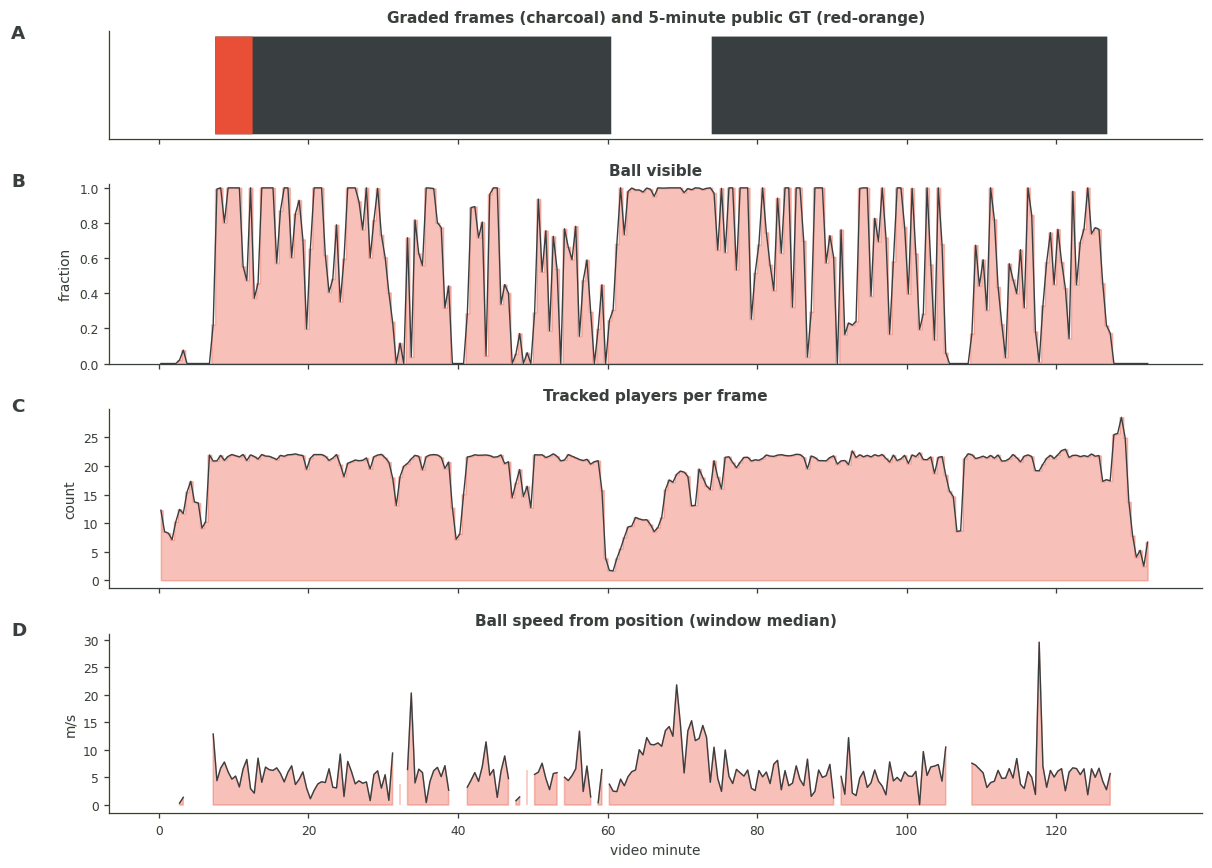

In [4]:
W = 30 * FPS
nwin = N // W
def win(x): return x[:nwin * W].reshape(nwin, W).astype(float)
tw = (np.arange(nwin) * W + W / 2) / FPS / 60

fig, ax = plt.subplots(4, 1, figsize=(11, 8), sharex=True, gridspec_kw=dict(height_ratios=[0.6, 1, 1, 1]))
ax[0].fill_between(MIN, GRADED, step="mid", color=C2, lw=0)
ax[0].fill_between(MIN, GRADED & (np.arange(N) <= 18684), step="mid", color=C1, lw=0)
ax[0].set(yticks=[], title="Graded frames (charcoal) and 5-minute public GT (red-orange)")
ax[1].fill_between(tw, win(BALL).mean(1), color=C1, alpha=0.35, step="mid"); ax[1].plot(tw, win(BALL).mean(1), color=C2, lw=0.9)
ax[1].set(ylim=(0, 1.02), ylabel="fraction", title="Ball visible")
ax[2].fill_between(tw, win(NPLAY).mean(1), color=C1, alpha=0.35, step="mid"); ax[2].plot(tw, win(NPLAY).mean(1), color=C2, lw=0.9)
ax[2].set(ylabel="count", title="Tracked players per frame")
bs = np.nanmedian(win(BSPEED), 1)
ax[3].plot(tw, bs, color=C2, lw=0.9); ax[3].fill_between(tw, bs, color=C1, alpha=0.35)
ax[3].set(ylabel="m/s", xlabel="video minute", title="Ball speed from position (window median)")
for a, l in zip(ax, "ABCD"): panel(a, l)
fig.tight_layout(); plt.show()

Ball visibility is **bimodal**: within a 30-s window the ball is either almost always visible or almost always missing, with many long ball-less blocks in both halves. The number of tracked players is stable at about 22 during play but drops sharply at half-time and at the start of the second half. Tracking quality depends on the moment in the game, not on time.

## [2] Missing ball: gap duration

A gap is a run of consecutive graded frames without the ball. Its duration distribution sets how far a previous state can safely be carried forward.

gaps: 150 | median 10.7 s | P90 33.8 s | max 221 s
gaps < 1 s: 11.3% | gaps > 10 s: 52.7% | share of missing frames in gaps > 10 s: 85.2%


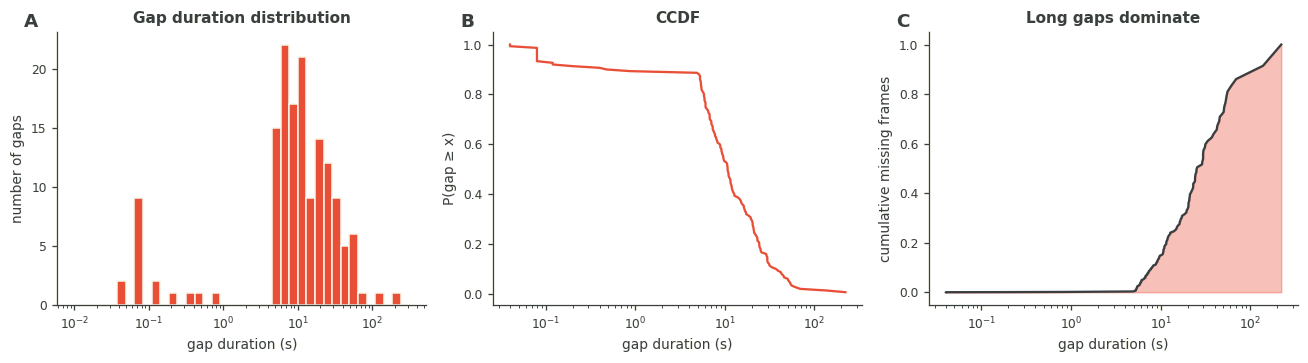

In [5]:
vis = BALL[GRADED]
edges = np.diff(np.concatenate(([1], vis.astype(int), [1])))
starts, ends = np.flatnonzero(edges == -1), np.flatnonzero(edges == 1)
gap = (ends - starts) / FPS
print(f"gaps: {len(gap)} | median {np.median(gap):.1f} s | P90 {np.percentile(gap, 90):.1f} s | max {gap.max():.0f} s")
print(f"gaps < 1 s: {np.mean(gap < 1):.1%} | gaps > 10 s: {np.mean(gap > 10):.1%} | share of missing frames in gaps > 10 s: {gap[gap > 10].sum() / gap.sum():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].hist(gap, bins=np.logspace(-2, 2.5, 40), color=C1, edgecolor=C3)
ax[0].set(xscale="log", xlabel="gap duration (s)", ylabel="number of gaps", title="Gap duration distribution")
g = np.sort(gap)[::-1]; ax[1].plot(g, np.arange(1, len(g) + 1) / len(g), color=C1)
ax[1].set(xscale="log", xlabel="gap duration (s)", ylabel="P(gap ≥ x)", title="CCDF")
cum = np.cumsum(np.sort(gap)) / gap.sum()
ax[2].plot(np.sort(gap), cum, color=C2); ax[2].fill_between(np.sort(gap), cum, color=C1, alpha=0.35)
ax[2].set(xscale="log", xlabel="gap duration (s)", ylabel="cumulative missing frames", title="Long gaps dominate")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Gaps are mostly **long**: only about 11% last under 1 s, the median is 10.7 s, and 85% of all ball-less frames come from gaps longer than 10 s (panel C). Holding the previous state is unsafe over gaps that long: a dead ball or a change of possession almost certainly happens inside them. Long gaps need another source of information (player positions, Smart Tagging, or the ball from video), not just interpolation.

## [3] Where the ball is lost

Panel A maps the last known ball position before each gap starts. Panel B maps the probability that the ball is missing one second later, per pitch cell, computed from frames where the ball is visible.

P(ball missing 1 s later | visible) = 3.6%


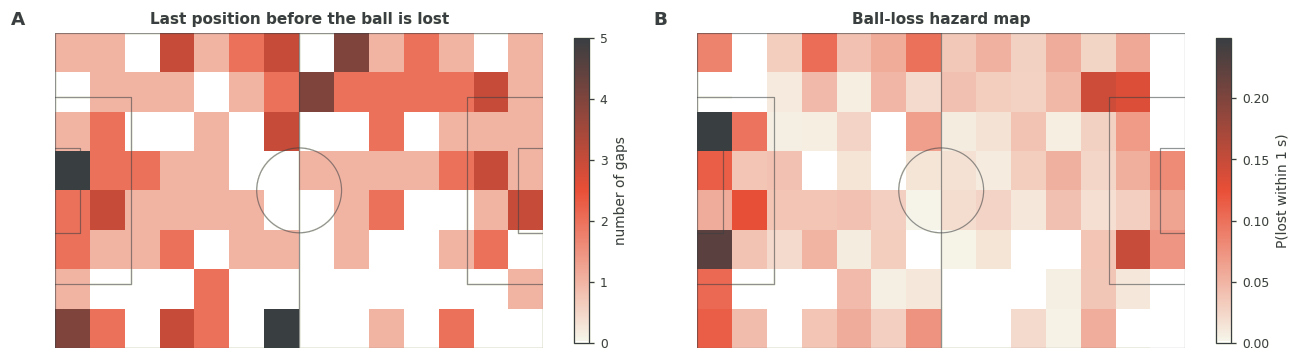

In [6]:
gidx = np.flatnonzero(GRADED)
last = gidx[starts[starts > 0] - 1]                       # last frame with the ball visible before the gap
lx, ly = BX[last], BY[last]

vis_i = np.flatnonzero(GRADED & BALL)
vis_i = vis_i[vis_i + FPS < N]
lost = ~BALL[vis_i + FPS]
bins = (np.linspace(0, LEN, 15), np.linspace(0, WID, 9))
num, _, _ = np.histogram2d(BX[vis_i][lost], BY[vis_i][lost], bins=bins)
den, _, _ = np.histogram2d(BX[vis_i], BY[vis_i], bins=bins)
haz = np.where(den > 200, num / np.maximum(den, 1), np.nan)
print(f"P(ball missing 1 s later | visible) = {lost.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
h = ax[0].hist2d(lx, ly, bins=bins, cmap=CMAP)[3]; plt.colorbar(h, ax=ax[0], shrink=0.75, label="number of gaps")
pitch(ax[0]); ax[0].set_title("Last position before the ball is lost")
m = ax[1].pcolormesh(bins[0], bins[1], haz.T, cmap=CMAP, vmin=0); plt.colorbar(m, ax=ax[1], shrink=0.75, label="P(lost within 1 s)")
pitch(ax[1]); ax[1].set_title("Ball-loss hazard map")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

The probability of losing the ball within one second is only 3.6% on average, so loss is not per-frame noise: once the ball is gone it tends to stay gone (consistent with the long gaps). Maps A and B show the zones where losses concentrate. A model should treat "ball missing" as a state with a duration.

## [4] Player-track quality

Three checks: number of tracked players, tracklet length per slot, and impossible position jumps (more than 2 m in 1/25 s, i.e. above 50 m/s) as a marker of identity swaps.

tracklets: 2218 | median 13.6 s | P90 201 s | max 2937 s
jumps > 2 m: 83 on graded frames (0.52 per 1000 frames)


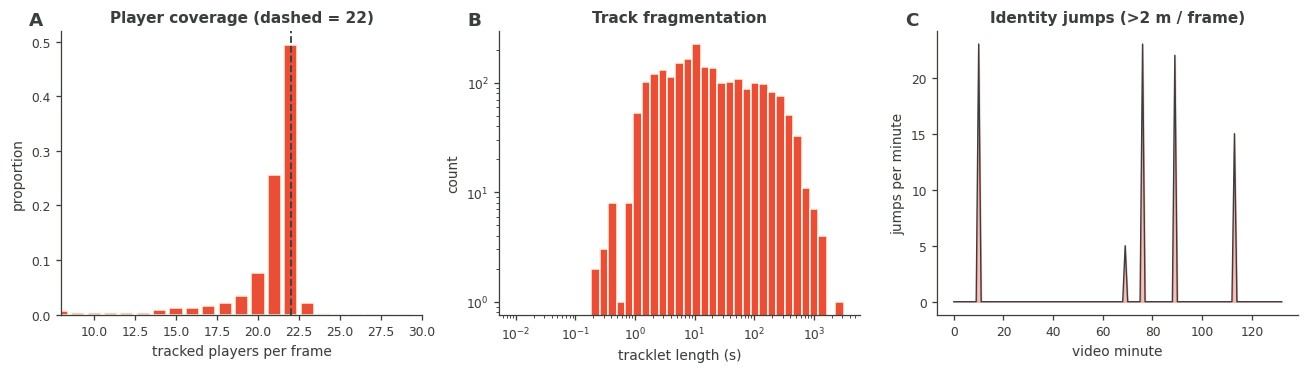

In [7]:
# tracklet length: run of consecutive frames in which a slot is present
tl = []
for s in range(46):
    e = np.diff(np.concatenate(([0], PRES[:, s].astype(int), [0])))
    tl.extend((np.flatnonzero(e == -1) - np.flatnonzero(e == 1)) / FPS)
tl = np.array(tl)

# jump: slot present in two consecutive frames but moved > 2 m
d = np.hypot(np.diff(PX, axis=0), np.diff(PY, axis=0))
jump = np.nan_to_num(d) > 2.0
jump_min = pd.Series(jump.sum(1)).groupby(np.arange(N - 1) // (FPS * 60)).sum()
print(f"tracklets: {len(tl)} | median {np.median(tl):.1f} s | P90 {np.percentile(tl, 90):.0f} s | max {tl.max():.0f} s")
print(f"jumps > 2 m: {int(jump[GRADED[:-1]].sum())} on graded frames ({jump[GRADED[:-1]].sum() / GRADED.sum() * 1000:.2f} per 1000 frames)")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
cnt = np.bincount(NPLAY[GRADED], minlength=30)[:30]
ax[0].bar(np.arange(30), cnt / cnt.sum(), color=C1, edgecolor=C3)
ax[0].axvline(22, color=WARM, lw=1.2, ls="--")
ax[0].set(xlabel="tracked players per frame", ylabel="proportion", title="Player coverage (dashed = 22)", xlim=(8, 30))
ax[1].hist(tl, bins=np.logspace(-2, 3.5, 40), color=C1, edgecolor=C3)
ax[1].set(xscale="log", yscale="log", xlabel="tracklet length (s)", ylabel="count", title="Track fragmentation")
ax[2].plot(jump_min.index, jump_min.values, color=C2, lw=0.9); ax[2].fill_between(jump_min.index, jump_min.values, color=C1, alpha=0.35)
ax[2].set(xlabel="video minute", ylabel="jumps per minute", title="Identity jumps (>2 m / frame)")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

Player coverage averages 20.5 (maximum 25, because of duplicates). Tracklets have a median of 13.6 s but are very heterogeneous (P90 about 200 s): some slots are stable, others fragmented. Impossible jumps are rare (about 0.5 per 1000 frames), but slots are still not players. Collective per-team features (nearest team distance to the ball) are safer than per-player features.

## [5] Ball–player geometry

The basic feature already used by the baseline: the distance to the nearest player of each team. The difference between the two distances (the *margin*) measures how contested the ball is: a small margin means both teams are equally close.

frames with the ball and >=1 player per team: 99.8%
nearest distance  median 1.9 m | P90 7.0 m
margin            median 3.5 m | margin < 2 m: 32.5%


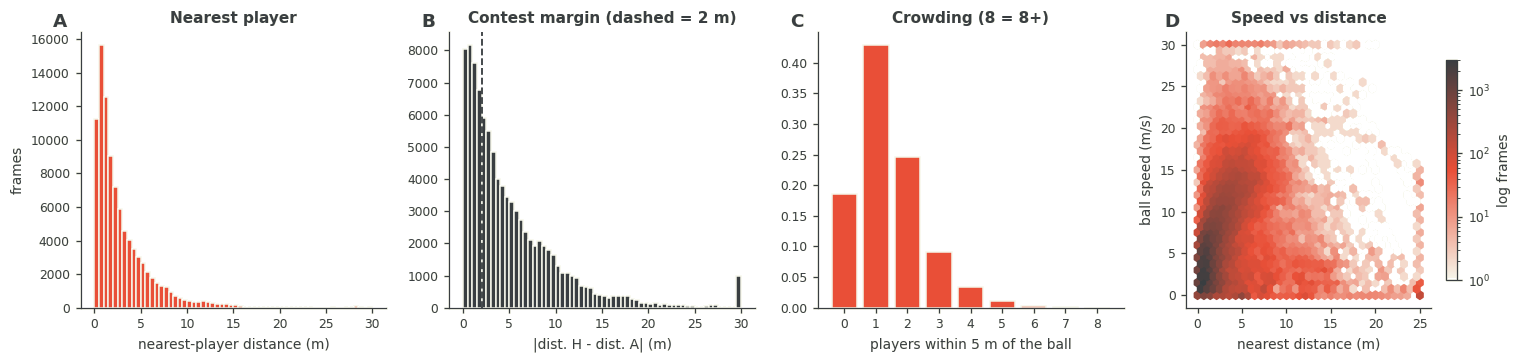

In [8]:
idx = np.flatnonzero(GRADED & BALL)
dx = PX[idx] - BX[idx, None]; dy = PY[idx] - BY[idx, None]
D = np.hypot(dx, dy)
D[~PRES[idx]] = np.inf
dh = np.where(T[None] == 0, D, np.inf).min(1)
da = np.where(T[None] == 1, D, np.inf).min(1)
near = np.minimum(dh, da)
margin = np.abs(dh - da)
within5 = (D < 5).sum(1)
ball_speed = BSPEED[idx]
ok = np.isfinite(near) & np.isfinite(margin)
print(f"frames with the ball and >=1 player per team: {ok.mean():.1%}")
print(f"nearest distance  median {np.median(near[ok]):.1f} m | P90 {np.percentile(near[ok], 90):.1f} m")
print(f"margin            median {np.median(margin[ok]):.1f} m | margin < 2 m: {np.mean(margin[ok] < 2):.1%}")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
ax[0].hist(np.clip(near[ok], 0, 30), bins=60, color=C1, edgecolor=C3); ax[0].set(xlabel="nearest-player distance (m)", ylabel="frames", title="Nearest player")
ax[1].hist(np.clip(margin[ok], 0, 30), bins=60, color=C2, edgecolor=C3); ax[1].axvline(2, color=WARM, ls="--", lw=1.2)
ax[1].set(xlabel="|dist. H - dist. A| (m)", title="Contest margin (dashed = 2 m)")
bc = np.bincount(np.clip(within5, 0, 8), minlength=9); ax[2].bar(range(9), bc / bc.sum(), color=C1, edgecolor=C3)
ax[2].set(xlabel="players within 5 m of the ball", title="Crowding (8 = 8+)", xticks=range(9))
hb = ax[3].hexbin(np.clip(near[ok], 0, 25), np.clip(ball_speed[ok], 0, 30), gridsize=35, cmap=CMAP, bins="log", mincnt=1)
plt.colorbar(hb, ax=ax[3], shrink=0.8, label="log frames"); ax[3].set(xlabel="nearest distance (m)", ylabel="ball speed (m/s)", title="Speed vs distance")
for a, l in zip(ax, "ABCD"): panel(a, l)
fig.tight_layout(); plt.show()

On frames where the ball is visible, the nearest player is about 1.9 m away (median) and 7 m at P90. In a third of frames (32.5%) the nearest players of the two teams are within 2 m of each other's distance: an ambiguous contest. That is exactly where "nearest player" fails most easily, so temporal evidence (who held the ball before) is more reliable than a per-frame decision.

## [6] Team shape and direction

Team positions per half reveal the direction of attack (the goal sides swap in the second half) and the formation's length and width over time. The direction of attack is needed for any later feature such as "ball in the final third".

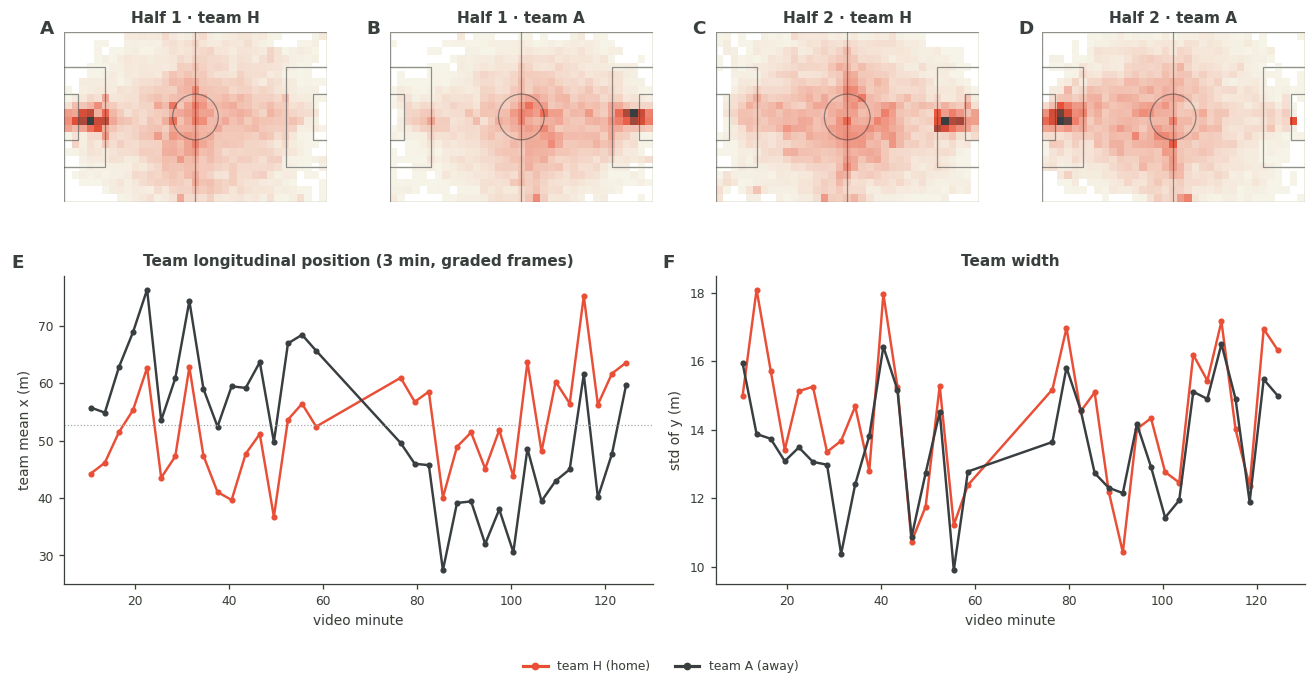

In [9]:
def team_xy(team, a, b):
    m = (T == team)[None] & PRES[a:b + 1]
    return PX[a:b + 1][m], PY[a:b + 1][m]

fig = plt.figure(figsize=(12, 7.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1.35, 1])
cells_ = [(0, 0), (0, 1), (0, 2), (0, 3)]
k = 0
for half, a, b in BLOCKS:
    for team, nm in ((0, "H"), (1, "A")):
        ax = fig.add_subplot(gs[0, k]); k += 1
        x, y = team_xy(team, a, b)
        h = ax.hist2d(x, y, bins=(np.linspace(0, LEN, 36), np.linspace(0, WID, 23)), cmap=CMAP)[3]
        pitch(ax); ax.set_title(f"Half {half} · team {nm}")
        panel(ax, "ABCD"[k - 1])

WW = 4500   # 3 minutes
starts_w = [s for s in range(0, N - WW, WW) if GRADED[s:s + WW].all()]
tw3 = (np.array(starts_w) + WW / 2) / FPS / 60
def tstat(team, fn, arr):
    return np.array([fn(np.where((T == team)[None] & PRES[s:s + WW], arr[s:s + WW], np.nan)) for s in starts_w])
ax = fig.add_subplot(gs[1, :2])
for team, c, nm in ((0, C1, "H"), (1, C2, "A")):
    ax.plot(tw3, tstat(team, np.nanmean, PX), color=c, lw=1.6, marker="o", ms=3, label=f"team {nm}")
ax.axhline(LEN / 2, color=GREY, lw=0.8, ls=":")
ax.set(xlabel="video minute", ylabel="team mean x (m)", title="Team longitudinal position (3 min, graded frames)")
panel(ax, "E")
ax = fig.add_subplot(gs[1, 2:])
for team, c, nm in ((0, C1, "H"), (1, C2, "A")):
    ax.plot(tw3, tstat(team, np.nanstd, PY), color=c, lw=1.6, marker="o", ms=3, label=f"team {nm}")
ax.set(xlabel="video minute", ylabel="std of y (m)", title="Team width"); panel(ax, "F")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([0], [0], color=C1, lw=2, marker="o", ms=4, label="team H (home)"), Line2D([0], [0], color=C2, lw=2, marker="o", ms=4, label="team A (away)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0))
fig.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

The highest density sits in front of each team's own goal (the goalkeeper), and the sides **swap** between halves: the home team defends the left goal in the first half and the right goal in the second, and the away team the opposite. The direction of attack therefore has to be set per half. The teams' mean positions oscillate with whoever is attacking.

## [7] Smart Tagging

638 automatically generated phases of play and dead-ball events. The intervals are *phases*, not possessions, and the `Team` tag is sometimes `N/A`.

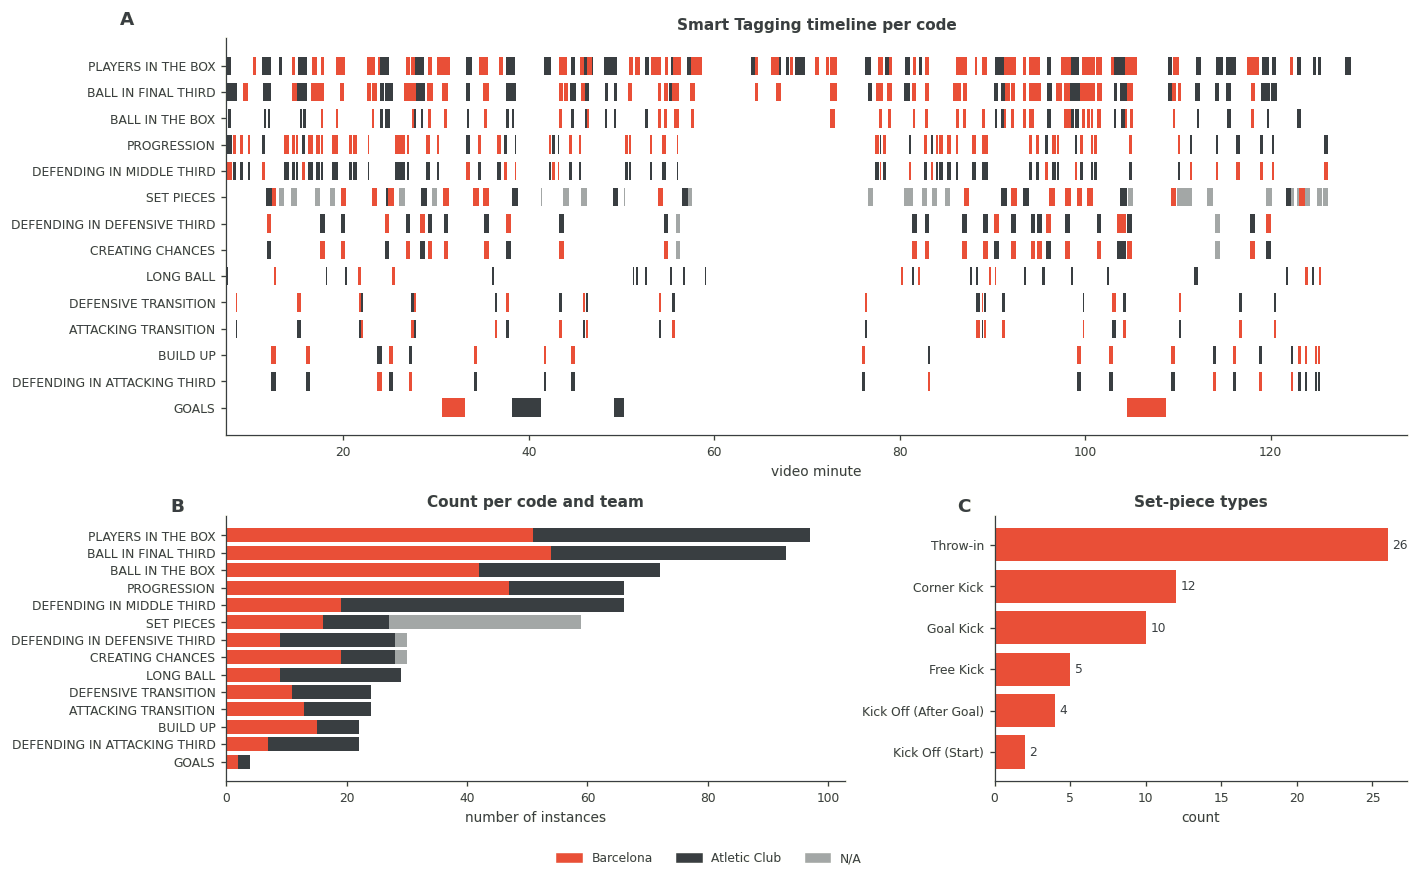

                              count   mean    50%    max
code                                                    
ATTACKING TRANSITION           24.0   15.5   15.4   22.0
BALL IN FINAL THIRD            93.0   30.1   27.0   70.8
BALL IN THE BOX                72.0   18.1   17.4   32.5
BUILD UP                       22.0   20.0   20.5   28.6
CREATING CHANCES               30.0   30.0   30.0   30.0
DEFENDING IN ATTACKING THIRD   22.0   20.0   20.5   28.6
DEFENDING IN DEFENSIVE THIRD   30.0   30.0   30.0   30.0
DEFENDING IN MIDDLE THIRD      66.0   18.9   17.6   37.1
DEFENSIVE TRANSITION           24.0   15.5   15.4   22.0
GOALS                           4.0  165.0  169.3  250.7
LONG BALL                      29.0   13.1   12.4   22.2
PLAYERS IN THE BOX             97.0   35.5   27.7   83.7
PROGRESSION                    66.0   18.9   17.6   37.1
SET PIECES                     59.0   31.9   35.0   35.0

intervals shared by two codes (twins):
code
(DEFENDING IN MIDDLE THIRD, PROGRESSION)   

In [10]:
from load_smart_tagging import load as load_tags
raw = load_tags()
tags = pd.DataFrame([{**{k: v for k, v in t.items() if k != "tags"}, **t["tags"]} for t in raw])
tags["dur"] = (tags.end_s - tags.start_s)
tags["t_min"] = tags.start_s / 60
order = tags.code.value_counts().index.tolist()
tcol = {"Barcelona": C1, "Atletic Club": C2, "N/A": GREY}

fig = plt.figure(figsize=(13, 8))
gs = fig.add_gridspec(2, 2, height_ratios=[1.5, 1], width_ratios=[1.5, 1])
ax = fig.add_subplot(gs[0, :])
for yi, code in enumerate(order[::-1]):
    sub = tags[tags.code == code]
    for _, r in sub.iterrows():
        ax.barh(yi, r.dur / 60, left=r.t_min, height=0.7, color=tcol.get(r.Team, GREY))
ax.set(yticks=range(len(order)), yticklabels=order[::-1], xlabel="video minute", title="Smart Tagging timeline per code")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=c, label=nm) for nm, c in tcol.items()], loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0))
panel(ax, "A")

ax = fig.add_subplot(gs[1, 0])
ct = pd.crosstab(tags.code, tags.Team).reindex(order)[["Barcelona", "Atletic Club", "N/A"]]
left = np.zeros(len(ct))
for nm in ct.columns:
    ax.barh(range(len(ct)), ct[nm], left=left, color=tcol[nm], label=nm); left += ct[nm].values
ax.set(yticks=range(len(ct)), yticklabels=ct.index, xlabel="number of instances", title="Count per code and team", xlim=(0, ct.sum(1).max() * 1.06)); ax.invert_yaxis(); panel(ax, "B")

ax = fig.add_subplot(gs[1, 1])
sp = tags[tags.code == "SET PIECES"]
spc = sp.Type.value_counts()
ax.barh(spc.index[::-1], spc.values[::-1], color=C1); ax.set(xlabel="count", title="Set-piece types")
for i, v in enumerate(spc.values[::-1]): ax.text(v + 0.3, i, str(v), va="center", fontsize=8)
panel(ax, "C"); fig.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

print(tags.groupby("code").dur.describe()[["count", "mean", "50%", "max"]].round(1).to_string())

pairs = tags.groupby(["start_frame", "end_frame"]).code.agg(lambda s: tuple(sorted(s)))
print("\nintervals shared by two codes (twins):")
print(pairs[pairs.map(len) == 2].value_counts().to_string())

Key finding: codes come in pairs. `PROGRESSION` and `DEFENDING IN MIDDLE THIRD`, `BUILD UP` and `DEFENDING IN ATTACKING THIRD`, `CREATING CHANCES` and `DEFENDING IN DEFENSIVE THIRD`, and `ATTACKING TRANSITION` and `DEFENSIVE TRANSITION` share **identical intervals** with opposite teams (142 twin intervals). So the `Team` tag on a "defending" code is the team that is **defending**, not the team in possession. `CREATING CHANCES` and `DEFENDING IN DEFENSIVE THIRD` also always last exactly 30 s, a sign of a fixed window rather than an event boundary. `Team = N/A` comes mainly from set pieces, the restarts where side information is needed most.

## [8] How reliable is the `Team` tag against geometry?

Without using the ground truth, the team tag is compared with the baseline label (nearest player, majority vote over ±50 frames). High agreement means the tag is a useful prior; disagreement marks places where one of the two is wrong.

In [11]:
from baseline import smooth
codes_all = common.cached("atd_nearest", lambda: None)
lab50 = smooth(codes_all, 50)                      # 'H' 'A' 'D' per frame

team_map = {"Barcelona": "H", "Atletic Club": "A"}
flip = {"H": "A", "A": "H"}
DEFENDER_CODES = {"DEFENDING IN ATTACKING THIRD", "DEFENDING IN MIDDLE THIRD", "DEFENDING IN DEFENSIVE THIRD", "DEFENSIVE TRANSITION"}
rows = []
for _, r in tags[tags.Team.isin(team_map)].iterrows():
    seg = lab50[r.start_frame:r.end_frame]
    alive = seg[(seg == "H") | (seg == "A")]
    tg = team_map[r.Team]
    pos = flip[tg] if r.code in DEFENDER_CODES else tg          # team presumed to be in possession
    rows.append({"code": r.code, "alive": len(alive) / max(len(seg), 1),
                 "agree_raw": (alive == tg).mean() if len(alive) else np.nan,
                 "agree": (alive == pos).mean() if len(alive) else np.nan})
ag = pd.DataFrame(rows)
res = ag.groupby("code").agg(n=("agree", "size"), agree_raw=("agree_raw", "mean"), agree=("agree", "mean"), alive=("alive", "mean")).sort_values("agree")
display(res.round(2))
print(f"raw agreement (Team as is): {ag.agree_raw.mean():.1%} | after flipping defending codes: {ag.agree.mean():.1%}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax[0].barh(res.index, res.agree, color=C1); ax[0].axvline(0.5, color=WARM, ls="--", lw=1.2)
ax[0].set(xlim=(0, 1), xlabel="agreement of tagged possessing team vs baseline", title="Per code (dashed = 0.5)")
ax[1].hist(ag.agree.dropna(), bins=20, color=C2, edgecolor=C3); ax[1].axvline(0.5, color=WARM, ls="--", lw=1.2)
ax[1].set(xlabel="agreement per phase", ylabel="number of phases", title="Distribution per phase (dashed = 0.5)")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()
pass

TypeError: object of type 'NoneType' has no len()

Reading `Team` as is agrees with the baseline only 53.7% of the time (close to chance), because "defending" codes name the defending side (raw agreement 16–35%). After flipping, overall agreement rises to 63.4%: `DEFENDING IN ATTACKING THIRD` 84% (same as `BUILD UP`), `DEFENDING IN MIDDLE THIRD` 76% (same as `PROGRESSION`), `DEFENSIVE TRANSITION` 65%. `GOALS`, `SET PIECES`, `PLAYERS IN THE BOX`, `CREATING CHANCES` and `DEFENDING IN DEFENSIVE THIRD` stay near 50%: short phases or dead balls, where the baseline is weakest anyway. The tag is a strong prior for flowing phases (`BUILD UP`, `PROGRESSION`) **if** the per-code `Team` semantics are handled correctly, and it is useless for throw-ins (`N/A`).

## [9] Correlation between candidate features

Spearman correlation matrix of the geometry features on frames where the ball is visible. Highly correlated features carry redundant information; nearly independent features are worth combining.

In [ ]:
feat = pd.DataFrame({
    "nearest dist.": near, "margin H-A": margin, "players <5 m": within5,
    "ball speed": ball_speed, "ball x": BX[idx], "ball y": BY[idx],
    "tracked players": NPLAY[idx], "dist. H": np.where(np.isfinite(dh), dh, np.nan),
    "dist. A": np.where(np.isfinite(da), da, np.nan),
}).replace([np.inf, -np.inf], np.nan)
corr = feat.corr(method="spearman")

fig, ax = plt.subplots(figsize=(6.4, 5.4))
mask = np.triu(np.ones_like(corr, bool), 1)
im = ax.imshow(np.ma.array(corr.values, mask=mask), cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticklabels(corr.index)
for i in range(len(corr)):
    for j in range(i + 1):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=7, color=INK)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Geometry feature correlation"); fig.tight_layout(); plt.show()

Nearest distance correlates positively with the home distance (0.65) and the away distance (0.47), and negatively with crowding within 5 m (−0.52), so the three are partly redundant. Ball speed (computed from position) correlates moderately with nearest distance (0.40): a fast-moving ball tends to be far from every player. Ball position (x, y) and the number of tracked players are nearly independent of local geometry (|ρ| < 0.1), so they carry different information.

## [10] Public ground truth: pipeline check

This section **only** confirms that frames line up and that labels mean what we think they mean. No threshold or rule is derived from it.

In [ ]:
import possession_metrics as pm
gt = pm.read_label_csv(ROOT / "evaluation" / "gt" / "BAR-ATH_possession_gt_public.csv")
lab = gt["label"].astype(str).values
sc = np.flatnonzero(lab != "X")
seg = pd.Series(lab[sc], index=sc)
run = (seg != seg.shift()).cumsum()
sp = seg.groupby(run).agg(label="first", n="size", start=lambda s: s.index[0])
sp["dur"] = sp.n / FPS
poss = sp[sp.label.isin(["H", "A"])]
print(f"graded frames {len(sc)} ({sc.min()}-{sc.max()}) | possessions {len(poss)} | mean duration {poss.dur.mean():.1f} s")
print(seg.value_counts().to_string())

fig, ax = plt.subplots(2, 1, figsize=(11, 3.4), gridspec_kw=dict(height_ratios=[0.7, 1]))
for _, r in sp.iterrows():
    ax[0].axvspan(r.start / FPS / 60, (r.start + r.n) / FPS / 60, color=TEAM[r.label])
ax[0].set(yticks=[], xlabel="video minute", title="Public GT: H (red-orange), A (charcoal), D (grey)"); ax[0].grid(False)
ax[1].bar(range(len(sp)), sp.dur, color=[TEAM[l] for l in sp.label]); ax[1].set(xlabel="segment order", ylabel="duration (s)", title="Segment duration")
panel(ax[0], "A"); panel(ax[1], "B"); fig.tight_layout(); plt.show()

Only 17 possessions in 5 minutes: far too few to choose between models (one missed possession moves spellF1 by about six points), but enough to check that the pipeline is correct.

## [11] Homography and broadcast

The tactical homography is valid on every frame. For a first look at camera quality, this section reads the broadcast homography, where part of the frames are invalid (replays, close-ups, crowd shots).

In [ ]:
hp = asset_paths(source="broadcast")["homography"]
hb = pd.read_csv(hp, usecols=["frame", "reprojection_error", "valid"])
v = hb.valid.values.astype(bool)
e = np.diff(np.concatenate(([1], v.astype(int), [1])))
inval = (np.flatnonzero(e == 1) - np.flatnonzero(e == -1)) / FPS
print(f"broadcast: {len(hb)} frames | valid {v.mean():.1%} | invalid stretches {len(inval)} | longest {inval.max():.0f} s")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3), gridspec_kw=dict(width_ratios=[1.8, 1, 1]))
bm = np.arange(len(hb)) / FPS / 60
w = 750
vw = v[:len(v) // w * w].reshape(-1, w).mean(1)
ax[0].fill_between(np.arange(len(vw)) * w / FPS / 60, vw, step="post", color=C1, alpha=0.35); ax[0].plot(np.arange(len(vw)) * w / FPS / 60, vw, color=C2, lw=0.9, drawstyle="steps-post")
ax[0].set(ylim=(0, 1.02), xlabel="broadcast minute", ylabel="valid fraction", title="Broadcast homography valid")
ax[1].hist(inval, bins=np.logspace(-1, 2.5, 30), color=C1, edgecolor=C3); ax[1].set(xscale="log", xlabel="invalid duration (s)", ylabel="count", title="Invalid stretches")
re = hb.reprojection_error.values[v]; ax[2].hist(np.clip(re, 0, 20), bins=50, color=C2, edgecolor=C3)
ax[2].set(xlabel="reprojection error (clipped at 20)", ylabel="frames", title="Reprojection error")
for a, l in zip(ax, "ABC"): panel(a, l)
fig.tight_layout(); plt.show()

The broadcast loses a third of its frames for homography, and its timeline is not aligned with the tactical one. Given the alignment cost, broadcast is best treated as an optional source, not a foundation.

# EDA Summary

Main findings, all computed on the ATD and Smart Tagging without using the ground truth for tuning:

1. **Evaluation scale.** Only 158,857 of 199,319 frames are graded (two halves); the rest are free `X`. The public ground truth has only 17 possessions: enough to check the pipeline, not to select a model.
2. **A missing ball is a state, not noise.** The ball is visible on 59.3% of graded frames. There are 150 gaps with a median of 10.7 s; only 11% last under 1 s, and 85% of all ball-less frames lie in gaps longer than 10 s. Interpolating or holding the previous state is not enough; the state model must use other sources during gaps.
3. **Player tracks are clean enough for collective features.** On average 20.5 players are tracked, tracklets have a median of 13.6 s with a long tail, and impossible jumps occur only about 0.5 times per 1000 frames. Slots are not players, so per-team features are safer.
4. **Local geometry is ambiguous on a third of frames.** The nearest player is a median 1.9 m away, but in 32.5% of frames the two teams' nearest players are within 2 m of each other. Per-frame decisions are weak there and temporal evidence is needed.
5. **The direction of attack swaps per half** (home goal on the left in half 1, on the right in half 2), so position features must be normalised per half.
6. **Smart Tagging is useful but has a semantic trap.** There are 142 twin intervals with opposite teams, and the `Team` tag on "defending" codes is the defending team. After flipping, agreement with the baseline rises from 53.7% to 63.4% (84% for `BUILD UP` / `DEFENDING IN ATTACKING THIRD`). Throw-ins are tagged `N/A`.
7. **Broadcast and homography.** The broadcast homography is valid on only 65.8% of frames (123 invalid stretches) and its timeline is not aligned, so broadcast stays optional.

Next step: a temporal state model over phases (H/A/D) with costly transitions, collective per-team evidence from ball–player geometry, state holding over short gaps, a Smart Tagging prior with the correct `Team` semantics, and evaluation on a possession metric rather than per frame. The experiments that followed are listed in [`../REGISTRY.md`](../REGISTRY.md).